In [1]:
import anndata as ad

sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated_hardcap.h5ad')


In [2]:
sc_data.obs[['sampled_st_x','sampled_st_y']].dropna()

,sampled_st_x,sampled_st_y
cell_ID_long,,
p1t1-bcIIOD-7,8304.666667,-141815.333333
p1t1-bcHTNA-7,12722.888889,-150600.333333
p1t1-bcDLAV-7,-2408.777778,-151159.333333
p1t1-bcHNVA-7,3990.444444,-156707.333333
p1t1-bcALZN-7,11496.888889,-150543.333333
...,...,...
p7t2-bcFAUI-6,-416.333333,3112.222222
p7t2-bcFHTY-6,-17105.000000,-1725.777778
p7t2-bcBHQQ-6,-13070.777778,-3127.777778


AnnData object with n_obs × n_vars = 322896 × 957
    obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Barcode', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'x_NSCLC_all_cells', 'y_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune', 'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune', 'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune', 'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode_Library', 'batch', 'cell_type', 'harmony_spatial_tissue', 'harmony_spatial_id', 'st_match_1_id', 'st_match_1_dist', 'st_match_1_x', 'st_match_1_y', 'st_match_2_id', 'st_match_2_dist', 'st_match_2_x', 'st_match_2_y', 'st_match_3_id', 'st_match_3_dist', 'st_match_3_x', 'st_match_3_y', 'sampled_st_id', 'sampled_st_x', 'sampled_st_y', 'selected_match_idx', 'spl

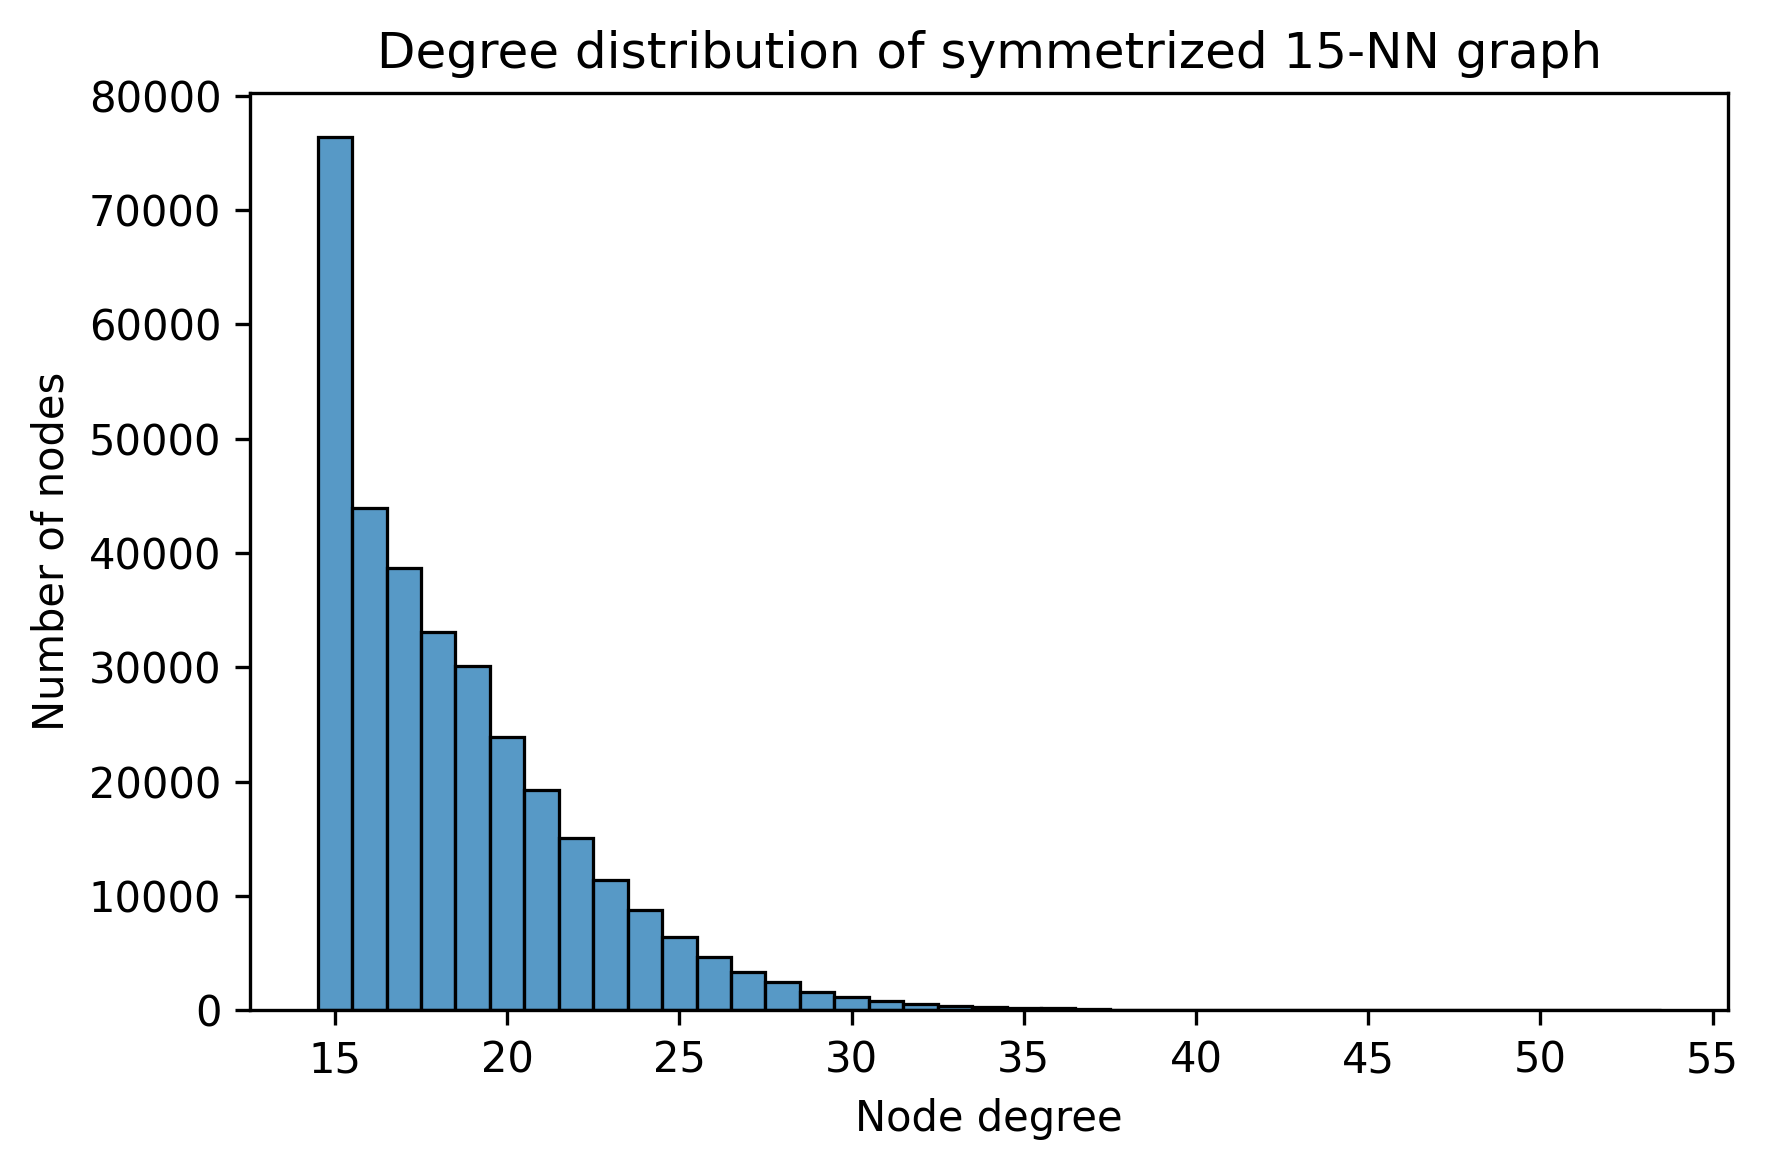

In [ ]:
tissues = sorted(sc_data.obs['harmony_spatial_tissue'].unique())

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import kneighbors_graph
degrees = []
tissues = sorted(sc_data.obs['harmony_spatial_tissue'].unique())

for t in tissues:
    # X should be shape: n_samples x n_features
    # Example:
    # X = adata.obsm["X_pca"]
    # X = coords
    # X = expression_matrix

    k = 15
    X = sc_data[sc_data.obs['harmony_spatial_tissue']==t].obs[['sampled_st_x','sampled_st_y']].dropna().values

    # Directed KNN graph: each node points to exactly k neighbors
    A_directed = kneighbors_graph(
        X,
        n_neighbors=k,
        mode="connectivity",
        include_self=False,
    )

    # Symmetrize to make an undirected graph
    # Edge exists if i is a neighbor of j OR j is a neighbor of i
    A = A_directed.maximum(A_directed.T)

    # Node degree = number of edges per node
    degrees.append(np.asarray(A.sum(axis=1)).ravel())

degrees= np.concatenate(degrees)
plt.figure(figsize=(6, 4),dpi=300)
sns.histplot(x=degrees, bins=np.arange(degrees.min(), degrees.max() + 2) - 0.5)
plt.xlabel("Node degree")
plt.ylabel("Number of nodes")
plt.title(f"Degree distribution of symmetrized {k}-NN graph")
plt.tight_layout()
plt.show()